In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [25]:
data = pd.read_csv('/content/drive/MyDrive/california_cities.csv')
data.head()

,Unnamed: 0,city,latd,longd,elevation_m,elevation_ft,population_total,area_total_sq_mi,area_land_sq_mi,area_water_sq_mi,area_total_km2,area_land_km2,area_water_km2,area_water_percent
0,0,Adelanto,34.576111,-117.432778,875.0,2871.0,31765,56.027,56.009,0.018,145.107,145.062,0.046,0.03
1,1,AgouraHills,34.153333,-118.761667,281.0,922.0,20330,7.822,7.793,0.029,20.260,20.184,0.076,0.37
2,2,Alameda,37.756111,-122.274444,NaN,33.0,75467,22.960,10.611,12.349,59.465,27.482,31.983,53.79
3,3,Albany,37.886944,-122.297778,NaN,43.0,18969,5.465,1.788,3.677,14.155,4.632,9.524,67.28
4,4,Alhambra,34.081944,-118.135000,150.0,492.0,83089,7.632,7.631,0.001,19.766,19.763,0.003,0.01


In [26]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 482 entries, 0 to 481
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Unnamed: 0          482 non-null    int64  
 1   city                482 non-null    object 
 2   latd                482 non-null    float64
 3   longd               482 non-null    float64
 4   elevation_m         434 non-null    float64
 5   elevation_ft        470 non-null    float64
 6   population_total    482 non-null    int64  
 7   area_total_sq_mi    480 non-null    float64
 8   area_land_sq_mi     482 non-null    float64
 9   area_water_sq_mi    481 non-null    float64
 10  area_total_km2      477 non-null    float64
 11  area_land_km2       478 non-null    float64
 12  area_water_km2      478 non-null    float64
 13  area_water_percent  477 non-null    float64
dtypes: float64(11), int64(2), object(1)
memory usage: 52.8+ KB


In [27]:
data.isna().sum()

,0
Unnamed: 0,0
city,0
latd,0
longd,0
elevation_m,48
elevation_ft,12
population_total,0
area_total_sq_mi,2
area_land_sq_mi,0
area_water_sq_mi,1


**handling the missing values**

Some cities with missing values might belong in the top five, so we shouldn't ignore them.
We can use area_water_sq_mi and convert square miles to square kilometers.

1 mi^2 = 2.58999 km^2

In [28]:
data.loc[
    data['area_water_km2'].isnull(),
    ['city', 'area_water_sq_mi', 'area_water_km2']
]

,city,area_water_sq_mi,area_water_km2
237,LosAltos,0.000,NaN
370,SanFrancisco,185.020,NaN
393,SantaMonica,0.001,NaN
443,UnionCity,0.000,NaN


In [29]:
df = data.copy()

df['area_water_km2'] = df['area_water_km2'].fillna(
    df['area_water_sq_mi'] * 2.58999
)
df['area_water_km2'].isnull().sum()

np.int64(0)

**Find the top five cities again**

In [30]:
top_5_cities = df.nlargest(5, 'area_water_km2')
top_5_cities[['city', 'area_water_km2']]

,city,area_water_km2
370,SanFrancisco,479.19995
367,SanDiego,122.27000
239,LosAngeles,88.00000
285,NewportBeach,75.55700
93,Coronado,64.06200


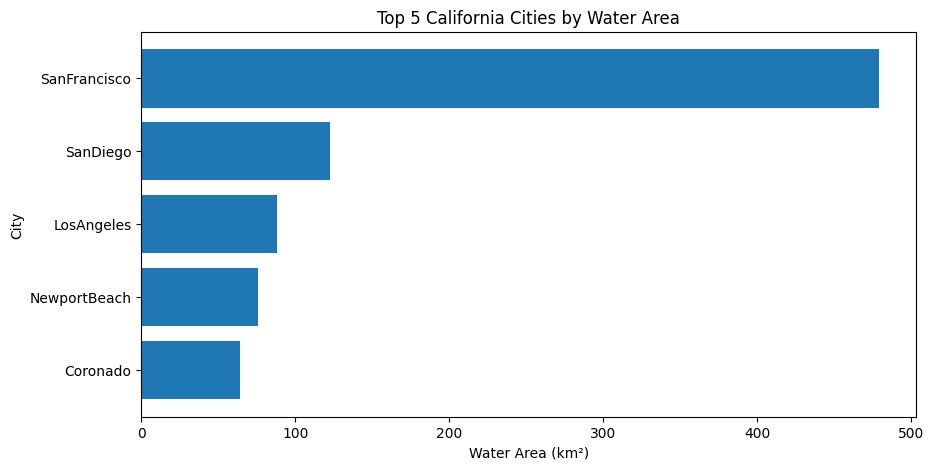

In [32]:
plt.figure(figsize=(10, 5))

plt.barh(
    top_5_cities['city'],
    top_5_cities['area_water_km2']
)

plt.xlabel('Water Area (km²)')
plt.ylabel('City')
plt.title('Top 5 California Cities by Water Area')

plt.gca().invert_yaxis()

plt.show()

This chart shows the five California cities with the largest water areas. The cities were ranked using the area_water_km2 column